In [1]:
# CELL 1 — Imports, reproducibility and project paths

from pathlib import Path
import json
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
)
from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Locate ml-workstream-2 whether Jupyter starts in project root or notebooks/.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        p for p in [cwd, *cwd.parents]
        if (p / "data" / "processed").is_dir()
        and (p / "notebooks").is_dir()
        and (p / "reports").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ml-workstream-2. Expected data/processed, notebooks and reports. "
        f"Current directory: {cwd}"
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in [TABLES_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FEATURE_TABLE_PATH = PROCESSED_DIR / "participant_phase_features.csv"
if not FEATURE_TABLE_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {FEATURE_TABLE_PATH}. Run Notebook 03 completely before Notebook 04."
    )

print("Project root:", PROJECT_ROOT)
print("Feature table:", FEATURE_TABLE_PATH)
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Random state:", RANDOM_STATE)


Project root: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2
Feature table: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\data\processed\participant_phase_features.csv
Python: 3.11.18
NumPy: 2.4.6 | pandas: 3.1.1 | scikit-learn: 1.9.1
Random state: 42


d:\Miniconda\envs\astronaut-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# CELL 2 — Load and validate participant-phase feature table

features_df = pd.read_csv(FEATURE_TABLE_PATH)
print(f"Loaded feature table: {len(features_df):,} rows × {features_df.shape[1]} columns")
print("Columns:", list(features_df.columns))

required_columns = {"participant_id", "phase", "target"}
missing_required = required_columns - set(features_df.columns)
if missing_required:
    raise KeyError(f"Required columns missing from processed table: {sorted(missing_required)}")

features_df["participant_id"] = features_df["participant_id"].astype("string").str.strip()
features_df["phase"] = features_df["phase"].astype("string").str.strip().str.lower()
features_df["target"] = pd.to_numeric(features_df["target"], errors="coerce")

# Re-derive labels from the documented experiment phase, then cross-check saved target.
phase_to_target = {"relax": 0, "stress": 1}
expected_target = features_df["phase"].map(phase_to_target)
if expected_target.isna().any():
    bad = sorted(features_df.loc[expected_target.isna(), "phase"].dropna().unique().tolist())
    raise ValueError(f"Unexpected or missing phase labels: {bad}")
if features_df["target"].isna().any() or not np.array_equal(
    features_df["target"].astype(int).to_numpy(), expected_target.astype(int).to_numpy()
):
    raise ValueError("Saved target column disagrees with phase labels. Recheck Notebook 03 output.")
features_df["target"] = expected_target.astype(int)

if features_df["participant_id"].isna().any() or (features_df["participant_id"] == "").any():
    raise ValueError("Missing participant IDs found; cannot run participant-independent validation.")
if features_df.duplicated(["participant_id", "phase"]).any():
    bad = features_df.loc[
        features_df.duplicated(["participant_id", "phase"], keep=False),
        ["participant_id", "phase"]
    ]
    display(bad)
    raise ValueError("Duplicate participant × phase rows found. Resolve before LOSO training.")

print("\nPhase counts:")
display(features_df["phase"].value_counts().rename_axis("phase").to_frame("rows"))
print("Unique participants:", features_df["participant_id"].nunique())
print("Participants with both phases:", int((features_df.groupby("participant_id")["target"].nunique() == 2).sum()))
print("\nRows per participant (summary):")
display(features_df.groupby("participant_id").size().describe().to_frame("rows_per_participant"))


Loaded feature table: 132 rows × 48 columns
Columns: ['source_row', 'participant_id', 'phase', 'ecg_sample_count', 'ecg_finite_sample_count', 'ecg_finite_fraction', 'ecg_duration_seconds', 'ecg_signal_std_export_units', 'ecg_signal_usable', 'ecg_device_heart_rate_bpm', 'ecg_mean_export_units', 'ecg_median_export_units', 'ecg_std_export_units', 'ecg_mad_export_units', 'ecg_iqr_export_units', 'ecg_q05_export_units', 'ecg_q95_export_units', 'ecg_min_export_units', 'ecg_max_export_units', 'ecg_peak_to_peak_export_units', 'ecg_rms_centered_export_units', 'ecg_abs_first_difference_mean', 'ecg_first_difference_std', 'ecg_skewness', 'ecg_excess_kurtosis', 'ecg_relative_power_low_0p5_40hz', 'ecg_relative_power_mid_0p5_40hz', 'ecg_relative_power_high_0p5_40hz', 'target', 'eda_total_rows', 'eda_valid_flag_true_rows', 'eda_valid_flag_false_rows', 'eda_valid_flag_unknown_rows', 'eda_valid_scl_rows', 'eda_scl_valid_fraction', 'eda_unique_time_markers', 'eda_repeated_time_rows', 'eda_recording_span_s

,rows
phase,
relax,66
stress,66


Unique participants: 66
Participants with both phases: 66

Rows per participant (summary):


,rows_per_participant
count,66.0
mean,2.0
std,0.0
min,2.0
25%,2.0
50%,2.0
75%,2.0
max,2.0


In [3]:
# CELL 3 — Define leak-safe modality feature sets and experiment cohorts

# Match the candidate model feature policy declared in Notebook 03.
ECG_QC_EXCLUSIONS = {
    "ecg_signal_usable",
    "ecg_sample_count",
    "ecg_finite_sample_count",
    "ecg_finite_fraction",
    "ecg_duration_seconds",
    "ecg_signal_std_export_units",
}
ECG_CANDIDATES = [
    c for c in features_df.columns
    if c.startswith("ecg_") and c not in ECG_QC_EXCLUSIONS
]
EDA_CANDIDATES = [
    c for c in [
        "eda_scl_mean_us",
        "eda_scl_median_us",
        "eda_scl_std_us",
        "eda_scl_mad_us",
        "eda_scl_iqr_us",
        "eda_scl_min_us",
        "eda_scl_max_us",
        "eda_scl_slope_us_per_sec",
    ]
    if c in features_df.columns
]

if not ECG_CANDIDATES:
    raise ValueError("No ECG model features found. Check Notebook 03 feature output.")
if not EDA_CANDIDATES:
    raise ValueError("No EDA model features found. Check Notebook 03 feature output.")

# Convert candidate inputs to numeric, and treat +/- infinity as missing.
for col in ECG_CANDIDATES + EDA_CANDIDATES:
    features_df[col] = pd.to_numeric(features_df[col], errors="coerce")
    features_df[col] = features_df[col].replace([np.inf, -np.inf], np.nan)

# Support function: require a feature to have observed values from >=2 distinct
# participants in the experiment cohort. This is not target-based feature selection.
def supported_features(frame, candidates, min_participants=2):
    supported = []
    dropped = {}
    for col in candidates:
        observed_groups = frame.loc[frame[col].notna(), "participant_id"].nunique()
        if observed_groups >= min_participants:
            supported.append(col)
        else:
            dropped[col] = int(observed_groups)
    return supported, dropped

# Build cohorts. An observation is usable for a modality if at least one feature
# from that modality is observed; rows are not retained merely because a recording exists.
base = features_df.loc[features_df["target"].isin([0, 1])].copy()
has_ecg = base[ECG_CANDIDATES].notna().any(axis=1)
has_eda = base[EDA_CANDIDATES].notna().any(axis=1)

cohort_masks = {
    "ECG — all eligible rows": has_ecg,
    "EDA — all available rows": has_eda,
    "ECG — paired cohort": has_ecg & has_eda,
    "EDA — paired cohort": has_ecg & has_eda,
    "ECG + EDA — paired cohort": has_ecg & has_eda,
}

experiment_specs = {}
for experiment_name, mask in cohort_masks.items():
    cohort = base.loc[mask].copy().reset_index(drop=True)
    if experiment_name.startswith("ECG") and "+ EDA" not in experiment_name:
        candidates = ECG_CANDIDATES
    elif experiment_name.startswith("EDA"):
        candidates = EDA_CANDIDATES
    else:
        candidates = ECG_CANDIDATES + EDA_CANDIDATES

    selected, dropped = supported_features(cohort, candidates)
    if not selected:
        print(f"Skipping {experiment_name}: no features supported by at least two participants.")
        continue

    # Remove any rows that have no observed input value in the selected feature set.
    cohort = cohort.loc[cohort[selected].notna().any(axis=1)].copy().reset_index(drop=True)
    if cohort["target"].nunique() < 2:
        print(f"Skipping {experiment_name}: cohort contains only one target class.")
        continue

    experiment_specs[experiment_name] = {
        "frame": cohort,
        "features": selected,
        "dropped_features": dropped,
    }

cohort_rows = []
for name, spec in experiment_specs.items():
    frame = spec["frame"]
    cohort_rows.append({
        "experiment": name,
        "rows": len(frame),
        "participants": frame["participant_id"].nunique(),
        "relax_rows": int((frame["target"] == 0).sum()),
        "stress_rows": int((frame["target"] == 1).sum()),
        "features": len(spec["features"]),
        "features_excluded_low_participant_support": len(spec["dropped_features"]),
    })
cohort_summary = pd.DataFrame(cohort_rows)
print("Experiment cohort summary:")
display(cohort_summary)

if not experiment_specs:
    raise ValueError("No eligible experiment cohorts could be constructed.")

print("\nECG candidate features:", ECG_CANDIDATES)
print("EDA candidate features:", EDA_CANDIDATES)


Experiment cohort summary:


,experiment,rows,participants,relax_rows,stress_rows,features,features_excluded_low_participant_support
0,ECG — all eligible rows,132,66,66,66,19,0
1,EDA — all available rows,124,64,64,60,8,0
2,ECG — paired cohort,124,64,64,60,19,0
3,EDA — paired cohort,124,64,64,60,8,0
4,ECG + EDA — paired cohort,124,64,64,60,27,0



ECG candidate features: ['ecg_device_heart_rate_bpm', 'ecg_mean_export_units', 'ecg_median_export_units', 'ecg_std_export_units', 'ecg_mad_export_units', 'ecg_iqr_export_units', 'ecg_q05_export_units', 'ecg_q95_export_units', 'ecg_min_export_units', 'ecg_max_export_units', 'ecg_peak_to_peak_export_units', 'ecg_rms_centered_export_units', 'ecg_abs_first_difference_mean', 'ecg_first_difference_std', 'ecg_skewness', 'ecg_excess_kurtosis', 'ecg_relative_power_low_0p5_40hz', 'ecg_relative_power_mid_0p5_40hz', 'ecg_relative_power_high_0p5_40hz']
EDA candidate features: ['eda_scl_mean_us', 'eda_scl_median_us', 'eda_scl_std_us', 'eda_scl_mad_us', 'eda_scl_iqr_us', 'eda_scl_min_us', 'eda_scl_max_us', 'eda_scl_slope_us_per_sec']


In [4]:
# CELL 4 — Define fold-local preprocessing and fixed baseline classifiers

# All imputation/scaling is fitted only on each fold's training participants.
def build_pipeline(model_name):
    steps = [("imputer", SimpleImputer(strategy="median"))]

    if model_name == "Logistic Regression":
        steps.append(("scaler", StandardScaler()))
        estimator = LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE,
        )
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=1,
            random_state=RANDOM_STATE,
        )
    elif model_name == "Gradient Boosting":
        estimator = GradientBoostingClassifier(
            n_estimators=80,
            learning_rate=0.03,
            max_depth=2,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")

    steps.append(("model", estimator))
    return Pipeline(steps)

MODEL_NAMES = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
print("Baseline estimators:")
for model_name in MODEL_NAMES:
    print(" -", model_name)

print("\nPipeline design:")
print(" - Median imputation: fitted inside each training fold")
print(" - Standard scaling: fitted inside each Logistic Regression training fold")
print(" - Tree models: no feature scaling")
print(" - No hyperparameter tuning or feature selection using held-out labels")


Baseline estimators:
 - Logistic Regression
 - Random Forest
 - Gradient Boosting

Pipeline design:
 - Median imputation: fitted inside each training fold
 - Standard scaling: fitted inside each Logistic Regression training fold
 - Tree models: no feature scaling
 - No hyperparameter tuning or feature selection using held-out labels


In [5]:
# CELL 5 — Smoke test one LOSO fold before the complete run

# This short check catches malformed feature matrices or missing classes before
# launching all model/fold combinations.
smoke_results = []
for experiment_name, spec in experiment_specs.items():
    frame = spec["frame"]
    groups = frame["participant_id"].astype(str).to_numpy()
    splitter = LeaveOneGroupOut()
    train_idx, test_idx = next(splitter.split(frame[spec["features"]], frame["target"], groups))

    X_train = frame.iloc[train_idx][spec["features"]]
    X_test = frame.iloc[test_idx][spec["features"]]
    y_train = frame.iloc[train_idx]["target"].astype(int)
    y_test = frame.iloc[test_idx]["target"].astype(int)

    if y_train.nunique() != 2:
        raise ValueError(f"Smoke test training fold for {experiment_name} does not contain both classes.")

    model = build_pipeline("Logistic Regression")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    smoke_results.append({
        "experiment": experiment_name,
        "held_out_participant": ", ".join(sorted(set(groups[test_idx]))),
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "test_predictions": pred.tolist(),
        "test_truth": y_test.tolist(),
    })

print("Smoke test successful. One LOSO fold fitted and predicted for each experiment:")
display(pd.DataFrame(smoke_results))


Smoke test successful. One LOSO fold fitted and predicted for each experiment:


,experiment,held_out_participant,train_rows,test_rows,test_predictions,test_truth
0,ECG — all eligible rows,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,130,2,"[1, 1]","[0, 1]"
1,EDA — all available rows,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,123,1,[1],[0]
2,ECG — paired cohort,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,123,1,[1],[0]
3,EDA — paired cohort,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,123,1,[1],[0]
4,ECG + EDA — paired cohort,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,123,1,[1],[0]


In [6]:
# CELL 6 — Run complete Leave-One-Subject-Out baseline experiments

# Each participant is held out exactly once per experiment/model. Predictions
# are accumulated out-of-fold; no participant contributes to their own training fold.
all_predictions = []
all_fold_metrics = []
run_started = time.perf_counter()

number_of_runs = len(experiment_specs) * len(MODEL_NAMES)
run_counter = 0

for experiment_name, spec in experiment_specs.items():
    frame = spec["frame"].reset_index(drop=True)
    feature_cols = spec["features"]
    X = frame[feature_cols]
    y = frame["target"].astype(int)
    groups = frame["participant_id"].astype(str)
    logo = LeaveOneGroupOut()
    expected_folds = groups.nunique()

    print(f"\n=== {experiment_name} | {len(frame)} rows | {expected_folds} participants | {len(feature_cols)} features ===", flush=True)

    for model_name in MODEL_NAMES:
        run_counter += 1
        model_started = time.perf_counter()
        print(f"Run {run_counter}/{number_of_runs}: {model_name}", flush=True)
        pipeline = build_pipeline(model_name)
        fold_iterator = tqdm(
            logo.split(X, y, groups),
            total=expected_folds,
            desc=f"{experiment_name[:24]} / {model_name}",
            leave=False,
        )

        fold_num = 0
        for train_idx, test_idx in fold_iterator:
            fold_num += 1
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
            test_groups = groups.iloc[test_idx]

            # Both classes should remain in training because every held-out fold
            # contains one participant, while the study has multiple participants.
            if y_train.nunique() < 2:
                raise ValueError(
                    f"Only one class in training fold {fold_num} for {experiment_name}/{model_name}."
                )

            fitted = clone(pipeline)
            fitted.fit(X_train, y_train)
            y_pred = fitted.predict(X_test).astype(int)
            probabilities = fitted.predict_proba(X_test)[:, list(fitted.named_steps["model"].classes_).index(1)]

            for local_idx, row_idx in enumerate(test_idx):
                all_predictions.append({
                    "experiment": experiment_name,
                    "model": model_name,
                    "participant_id": str(groups.iloc[row_idx]),
                    "phase": str(frame.iloc[row_idx]["phase"]),
                    "y_true": int(y_test.iloc[local_idx]),
                    "y_pred": int(y_pred[local_idx]),
                    "stress_probability": float(probabilities[local_idx]),
                    "fold": fold_num,
                })

            fold_cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
            all_fold_metrics.append({
                "experiment": experiment_name,
                "model": model_name,
                "held_out_participant": ", ".join(sorted(set(test_groups.astype(str)))),
                "n_test_rows": len(test_idx),
                "fold_accuracy": accuracy_score(y_test, y_pred),
                "fold_balanced_accuracy": balanced_accuracy_score(y_test, y_pred) if y_test.nunique() == 2 else np.nan,
                "fold_relax_recall": recall_score(y_test, y_pred, labels=[0, 1], average=None, zero_division=0)[0],
                "fold_stress_recall": recall_score(y_test, y_pred, labels=[0, 1], average=None, zero_division=0)[1],
                "tn": int(fold_cm[0, 0]),
                "fp": int(fold_cm[0, 1]),
                "fn": int(fold_cm[1, 0]),
                "tp": int(fold_cm[1, 1]),
            })

        elapsed = time.perf_counter() - model_started
        print(f"Completed {model_name} in {elapsed:.1f} seconds.", flush=True)

elapsed_total = time.perf_counter() - run_started
predictions_df = pd.DataFrame(all_predictions)
fold_metrics_df = pd.DataFrame(all_fold_metrics)

print(f"\nAll LOSO runs completed in {elapsed_total:.1f} seconds.")
print("Out-of-fold predictions:", predictions_df.shape)
print("Fold metrics:", fold_metrics_df.shape)



=== ECG — all eligible rows | 132 rows | 66 participants | 19 features ===
Run 1/15: Logistic Regression


Completed Logistic Regression in 0.8 seconds.
Run 2/15: Random Forest


Completed Random Forest in 12.3 seconds.
Run 3/15: Gradient Boosting


Completed Gradient Boosting in 3.1 seconds.

=== EDA — all available rows | 124 rows | 64 participants | 8 features ===
Run 4/15: Logistic Regression


Completed Logistic Regression in 0.7 seconds.
Run 5/15: Random Forest


Completed Random Forest in 11.2 seconds.
Run 6/15: Gradient Boosting


... (6 outputs left out)

Completed Gradient Boosting in 2.6 seconds.

=== ECG + EDA — paired cohort | 124 rows | 64 participants | 27 features ===
Run 13/15: Logistic Regression


Completed Logistic Regression in 0.7 seconds.
Run 14/15: Random Forest


Completed Random Forest in 11.6 seconds.
Run 15/15: Gradient Boosting


Completed Gradient Boosting in 3.5 seconds.

All LOSO runs completed in 76.9 seconds.
Out-of-fold predictions: (1884, 8)
Fold metrics: (966, 12)


In [7]:
# CELL 7 — Calculate out-of-fold performance and per-participant results

comparison_rows = []
participant_rows = []

for (experiment_name, model_name), group in predictions_df.groupby(["experiment", "model"], sort=False):
    y_true = group["y_true"].to_numpy(dtype=int)
    y_pred = group["y_pred"].to_numpy(dtype=int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    class_recalls = recall_score(y_true, y_pred, labels=[0, 1], average=None, zero_division=0)

    comparison_rows.append({
        "experiment": experiment_name,
        "model": model_name,
        "n_observations": len(group),
        "n_participants": group["participant_id"].nunique(),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "relax_recall_specificity": float(class_recalls[0]),
        "stress_recall_sensitivity": float(class_recalls[1]),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    })

    for participant_id, pgroup in group.groupby("participant_id"):
        pt = pgroup["y_true"].to_numpy(dtype=int)
        pp = pgroup["y_pred"].to_numpy(dtype=int)
        has_both = len(np.unique(pt)) == 2
        pt_recalls = recall_score(pt, pp, labels=[0, 1], average=None, zero_division=0)
        participant_rows.append({
            "experiment": experiment_name,
            "model": model_name,
            "participant_id": participant_id,
            "n_observations": len(pgroup),
            "phases_present": int(len(np.unique(pt))),
            "accuracy": accuracy_score(pt, pp),
            "balanced_accuracy": balanced_accuracy_score(pt, pp) if has_both else np.nan,
            "relax_recall": float(pt_recalls[0]) if has_both else np.nan,
            "stress_recall": float(pt_recalls[1]) if has_both else np.nan,
        })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    ["experiment", "balanced_accuracy", "macro_f1"],
    ascending=[True, False, False]
).reset_index(drop=True)
participant_metrics_df = pd.DataFrame(participant_rows)

print("Out-of-fold model comparison (primary metric: balanced accuracy):")
display(comparison_df)
print("\nPer-participant results (first 25 rows):")
display(participant_metrics_df.head(25))

# Persist reproducible predictions and metric tables.
predictions_df.to_csv(TABLES_DIR / "loso_oof_predictions.csv", index=False)
fold_metrics_df.to_csv(TABLES_DIR / "loso_fold_metrics.csv", index=False)
participant_metrics_df.to_csv(TABLES_DIR / "loso_per_participant_metrics.csv", index=False)
comparison_df.to_csv(TABLES_DIR / "loso_model_comparison.csv", index=False)

feature_manifest = {
    name: {
        "n_rows": int(len(spec["frame"])),
        "n_participants": int(spec["frame"]["participant_id"].nunique()),
        "features": spec["features"],
        "excluded_features_low_participant_support": spec["dropped_features"],
    }
    for name, spec in experiment_specs.items()
}
(PROJECT_ROOT / "configs").mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT / "configs" / "baseline_model_feature_manifest.json").write_text(
    json.dumps(feature_manifest, indent=2), encoding="utf-8"
)

print("\nSaved:")
for path in [
    TABLES_DIR / "loso_oof_predictions.csv",
    TABLES_DIR / "loso_fold_metrics.csv",
    TABLES_DIR / "loso_per_participant_metrics.csv",
    TABLES_DIR / "loso_model_comparison.csv",
    PROJECT_ROOT / "configs" / "baseline_model_feature_manifest.json",
]:
    print(" -", path)


Out-of-fold model comparison (primary metric: balanced accuracy):


,experiment,model,n_observations,n_participants,balanced_accuracy,accuracy,macro_f1,relax_recall_specificity,stress_recall_sensitivity,tn,fp,fn,tp
0,ECG + EDA — paired cohort,Gradient Boosting,124,64,0.561979,0.564516,0.560399,0.640625,0.483333,41,23,31,29
1,ECG + EDA — paired cohort,Logistic Regression,124,64,0.531771,0.532258,0.531771,0.546875,0.516667,35,29,29,31
2,ECG + EDA — paired cohort,Random Forest,124,64,0.522917,0.524194,0.522672,0.562500,0.483333,36,28,31,29
3,ECG — all eligible rows,Gradient Boosting,132,66,0.598485,0.598485,0.596610,0.666667,0.530303,44,22,31,35
4,ECG — all eligible rows,Random Forest,132,66,0.575758,0.575758,0.573309,0.651515,0.500000,43,23,33,33
5,ECG — all eligible rows,Logistic Regression,132,66,0.477273,0.477273,0.476522,0.439394,0.515152,29,37,32,34
6,ECG — paired cohort,Gradient Boosting,124,64,0.601042,0.604839,0.597269,0.718750,0.483333,46,18,31,29
7,ECG — paired cohort,Random Forest,124,64,0.514062,0.516129,0.512962,0.578125,0.450000,37,27,33,27
8,ECG — paired cohort,Logistic Regression,124,64,0.483854,0.483871,0.483737,0.484375,0.483333,31,33,31,29
9,EDA — all available rows,Random Forest,124,64,0.693229,0.693548,0.693229,0.703125,0.683333,45,19,19,41



Per-participant results (first 25 rows):


,experiment,model,participant_id,n_observations,phases_present,accuracy,balanced_accuracy,relax_recall,stress_recall
0,ECG — all eligible rows,Logistic Regression,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec6...,2,2,0.5,0.5,0.0,1.0
1,ECG — all eligible rows,Logistic Regression,036e6da345803c97c92d64a489ecdfefd93adb7cd94743...,2,2,1.0,1.0,1.0,1.0
2,ECG — all eligible rows,Logistic Regression,06c274b06c4badedf4a5710f3af21a338af00c3ac3e6e1...,2,2,0.5,0.5,0.0,1.0
3,ECG — all eligible rows,Logistic Regression,09223ce6fe3b28d121bf18df0e4e8f09622209678abf7b...,2,2,0.5,0.5,0.0,1.0
4,ECG — all eligible rows,Logistic Regression,0e1d276d538d521abc42245a3920f6282c3279e0337caf...,2,2,0.5,0.5,0.0,1.0
5,ECG — all eligible rows,Logistic Regression,0f53170a435a716c32ea8392d549ba057b4e29c50bb12f...,2,2,0.5,0.5,0.0,1.0
6,ECG — all eligible rows,Logistic Regression,14bdb864e416460c7a92da08570929fe3d80a8688c8038...,2,2,0.5,0.5,1.0,0.0
7,ECG — all eligible rows,Logistic Regression,160146850768697cf9984655ffa2f956f10a1e41b1c7f2...,2,2,0.5,0.5,1.0,0.0
8,ECG — all eligible rows,Logistic Regression,17fc54dbc1172a9c00cc8a931412bc0b65dc3b51507cbb...,2,2,0.5,0.5,0.0,1.0
9,ECG — all eligible rows,Logistic Regression,23d08053659320558c3ceb47cd928d8ef2d07a4cc0eeb2...,2,2,0.5,0.5,1.0,0.0



Saved:
 - D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables\loso_oof_predictions.csv
 - D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables\loso_fold_metrics.csv
 - D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables\loso_per_participant_metrics.csv
 - D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables\loso_model_comparison.csv
 - D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\configs\baseline_model_feature_manifest.json


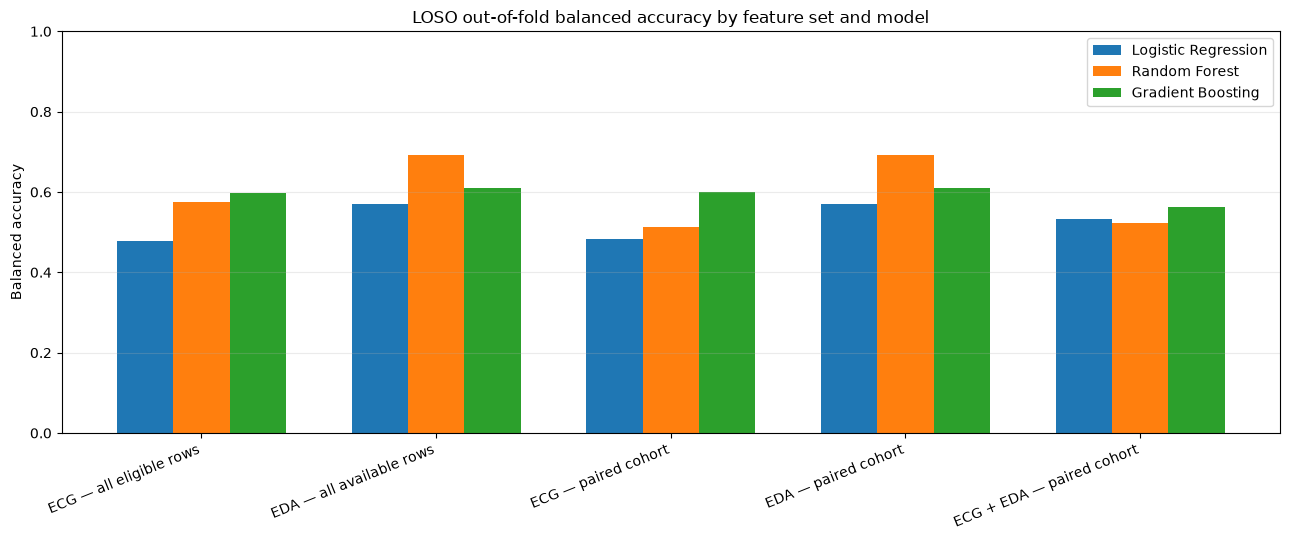

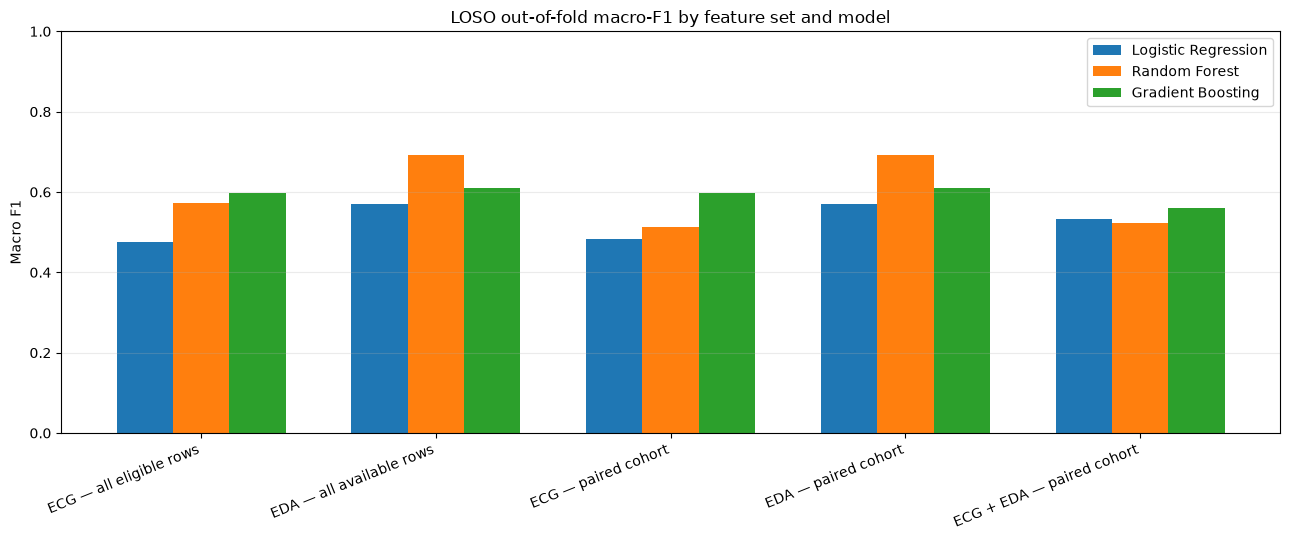

Saved comparison figures to: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\figures


In [8]:
# CELL 8 — Visualize the out-of-fold model comparison

# Plot balanced accuracy by experiment and model.
experiments_order = list(experiment_specs.keys())
models_order = MODEL_NAMES
x = np.arange(len(experiments_order))
width = 0.24

fig, ax = plt.subplots(figsize=(13, 5.5))
for model_idx, model_name in enumerate(models_order):
    values = []
    for experiment_name in experiments_order:
        row = comparison_df.loc[
            (comparison_df["experiment"] == experiment_name)
            & (comparison_df["model"] == model_name),
            "balanced_accuracy"
        ]
        values.append(float(row.iloc[0]) if len(row) else np.nan)
    ax.bar(x + (model_idx - 1) * width, values, width, label=model_name)

ax.set_ylabel("Balanced accuracy")
ax.set_title("LOSO out-of-fold balanced accuracy by feature set and model")
ax.set_xticks(x)
ax.set_xticklabels(experiments_order, rotation=22, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "loso_balanced_accuracy_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Plot macro-F1 by experiment and model.
fig, ax = plt.subplots(figsize=(13, 5.5))
for model_idx, model_name in enumerate(models_order):
    values = []
    for experiment_name in experiments_order:
        row = comparison_df.loc[
            (comparison_df["experiment"] == experiment_name)
            & (comparison_df["model"] == model_name),
            "macro_f1"
        ]
        values.append(float(row.iloc[0]) if len(row) else np.nan)
    ax.bar(x + (model_idx - 1) * width, values, width, label=model_name)

ax.set_ylabel("Macro F1")
ax.set_title("LOSO out-of-fold macro-F1 by feature set and model")
ax.set_xticks(x)
ax.set_xticklabels(experiments_order, rotation=22, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "loso_macro_f1_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved comparison figures to:", FIGURES_DIR)


In [9]:
# CELL 9 — Write the baseline training report and interpretation safeguards

report_lines = [
    "# Baseline Model Training Report",
    "",
    f"- Feature table: `{FEATURE_TABLE_PATH}`",
    f"- Python: {platform.python_version()}",
    f"- NumPy: {np.__version__}",
    f"- pandas: {pd.__version__}",
    f"- scikit-learn: {sklearn.__version__}",
    f"- Random state: {RANDOM_STATE}",
    f"- Total LOSO runtime: {elapsed_total:.1f} seconds",
    "",
    "## Evaluation method",
    "- Leave-One-Subject-Out cross-validation; all rows belonging to a held-out participant remain outside that fold's training set.",
    "- Median imputation is fitted inside each training fold; Logistic Regression scaling is also fitted inside each training fold.",
    "- No random row-level train/test split was used.",
    "- No hyperparameter search was performed; reported models are fixed baseline configurations.",
    "- Primary metric: balanced accuracy. Secondary metrics: macro-F1, accuracy, RELAX recall/specificity, STRESS recall/sensitivity.",
    "",
    "## Cohorts",
]
for _, row in cohort_summary.iterrows():
    report_lines.append(
        f"- {row['experiment']}: {row['rows']} rows, {row['participants']} participants, "
        f"RELAX={row['relax_rows']}, STRESS={row['stress_rows']}, {row['features']} features."
    )
report_lines += ["", "## Out-of-fold results", ""]
for _, row in comparison_df.iterrows():
    report_lines.append(
        f"- **{row['experiment']} / {row['model']}**: balanced accuracy={row['balanced_accuracy']:.3f}; "
        f"macro-F1={row['macro_f1']:.3f}; accuracy={row['accuracy']:.3f}; "
        f"RELAX recall={row['relax_recall_specificity']:.3f}; "
        f"STRESS recall={row['stress_recall_sensitivity']:.3f}; "
        f"n={row['n_observations']} observations / {row['n_participants']} participants."
    )
report_lines += [
    "",
    "## Outputs",
    "- `reports/tables/loso_model_comparison.csv`",
    "- `reports/tables/loso_oof_predictions.csv`",
    "- `reports/tables/loso_fold_metrics.csv`",
    "- `reports/tables/loso_per_participant_metrics.csv`",
    "- `reports/figures/loso_balanced_accuracy_comparison.png`",
    "- `reports/figures/loso_macro_f1_comparison.png`",
    "- `configs/baseline_model_feature_manifest.json`",
    "",
    "## Interpretation safeguards",
    "- This task predicts the dataset's controlled experimental RELAX/STRESS phase; it does not diagnose chronic stress or a mental-health condition.",
    "- This dataset is small and contains repeated observations from participants. LOSO reduces participant leakage but does not establish external generalization to astronauts or spaceflight.",
    "- The paired ECG/EDA cohort is used for fairer modality/fusion comparison. Compare ECG-only, EDA-only and fusion results on that matched cohort rather than comparing only their different full-availability cohorts.",
    "- The first best-scoring model is not automatically accepted as the final model. Review per-participant errors, class recalls, and stability before selecting it.",
    "- No final production model is exported by this notebook. Model selection and final refitting should happen only after error analysis and methodological review.",
    "- Fitbit data, STAI/PSS scores and demographics remain excluded from these physiological phase classifiers.",
    "",
    "## Dataset citation",
    "Calvo, A., Cejudo, A., & Martín Andonegui, C. (2026). *QoL_Stress: A Multimodal Dataset of Physiological and Self-Reported Stress Responses* (version 1.0.0). PhysioNet. https://doi.org/10.13026/vqtz-pm70",
]

report_path = REPORTS_DIR / "baseline_model_training_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved report:", report_path)
print("\nBaseline model training completed.")
print("Next: inspect matched-cohort results and per-participant errors before changing features or tuning models.")


Saved report: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\baseline_model_training_report.md

Baseline model training completed.
Next: inspect matched-cohort results and per-participant errors before changing features or tuning models.
